In [6]:
# Environment setup & Imports
import os, sys
sys.path.append(os.path.abspath('..'))
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML

from shared_utils.theme import PALETTE, apply_sleek_theme, create_dashboard_header
from cardiac_and_epileptor import (
    generate_synthetic_rr_intervals, compute_poincare_descriptors,
    compute_sample_entropy, simulate_epileptor_csd
)
from financial_lppls_and_rc import generate_lppls_bubble, EchoStateNetwork

apply_sleek_theme()
display(HTML(create_dashboard_header(
    'ACT 08: CLINICAL, FINANCIAL & AI CHAOS FRONTIERS',
    'Interactive GUI Suite: Cardiac HRV Poincare Plots, Epileptic CSD, LPPLS Market Crashes & Reservoir Computing'
)))

In [7]:
# LAB 8.1: CARDIAC HRV POINCARE GEOMETRY & SAMPLE ENTROPY
display(HTML(create_dashboard_header(
    'LAB 8.1: CARDIAC HRV DYNAMICS & POINCARE RETURN MAPS',
    'Toggle between healthy fractal physiology and pathological decay: Measure SD1, SD2, and Sample Entropy.'
)))

def render_cardiac_dashboard(cardiac_state):
    rr_data = generate_synthetic_rr_intervals(n_beats=900, state=cardiac_state.lower())
    rr_n, rr_next, sd1, sd2, ratio = compute_poincare_descriptors(rr_data)
    samp_en = compute_sample_entropy(rr_data[:500], m=2, r=0.2)
    
    fig, axs = plt.subplots(1, 2, figsize=(13, 5), dpi=100)
    
    # Panel A: RR Interval Tachogram
    axs[0].plot(rr_data, color=PALETTE['cyan'], lw=1.2, label='RR Intervals (ms)')
    axs[0].set_title(f'Tachogram ({cardiac_state}) | SampEn = {samp_en:.3f}', fontsize=11)
    axs[0].set_xlabel('Beat Index n', fontsize=10)
    axs[0].set_ylabel('RR Duration (ms)', fontsize=10)
    axs[0].set_ylim(650, 950)
    axs[0].legend(loc='upper right')
    
    # Panel B: Poincare Ellipse Geometry (RR_n vs RR_{n+1})
    axs[1].scatter(rr_n, rr_next, s=12, color=PALETTE['emerald'], alpha=0.6, label='Beat Pairs')
    axs[1].plot([680, 920], [680, 920], color=PALETTE['text_muted'], linestyle='--', lw=1.2, label='Identity Line')
    axs[1].set_title(f'Poincare Return Map | SD1 = {sd1:.1f} ms, SD2 = {sd2:.1f} ms (Ratio: {ratio:.2f})', fontsize=11)
    axs[1].set_xlabel('RR_n (ms)', fontsize=10)
    axs[1].set_ylabel('RR_{n+1} (ms)', fontsize=10)
    axs[1].set_xlim(680, 920)
    axs[1].set_ylim(680, 920)
    axs[1].legend(loc='upper left')
    
    plt.tight_layout()
    plt.show()

state_drop = widgets.Dropdown(options=['Healthy', 'Pathological'], value='Healthy', description='Cardiac State:')
ui_cardiac = widgets.HBox([state_drop], layout=widgets.Layout(padding='10px', background_color=PALETTE['surface'], border='1px solid ' + PALETTE['border'], border_radius='8px'))
out_cardiac = widgets.interactive_output(render_cardiac_dashboard, {'cardiac_state': state_drop})
display(ui_cardiac, out_cardiac)

Output()

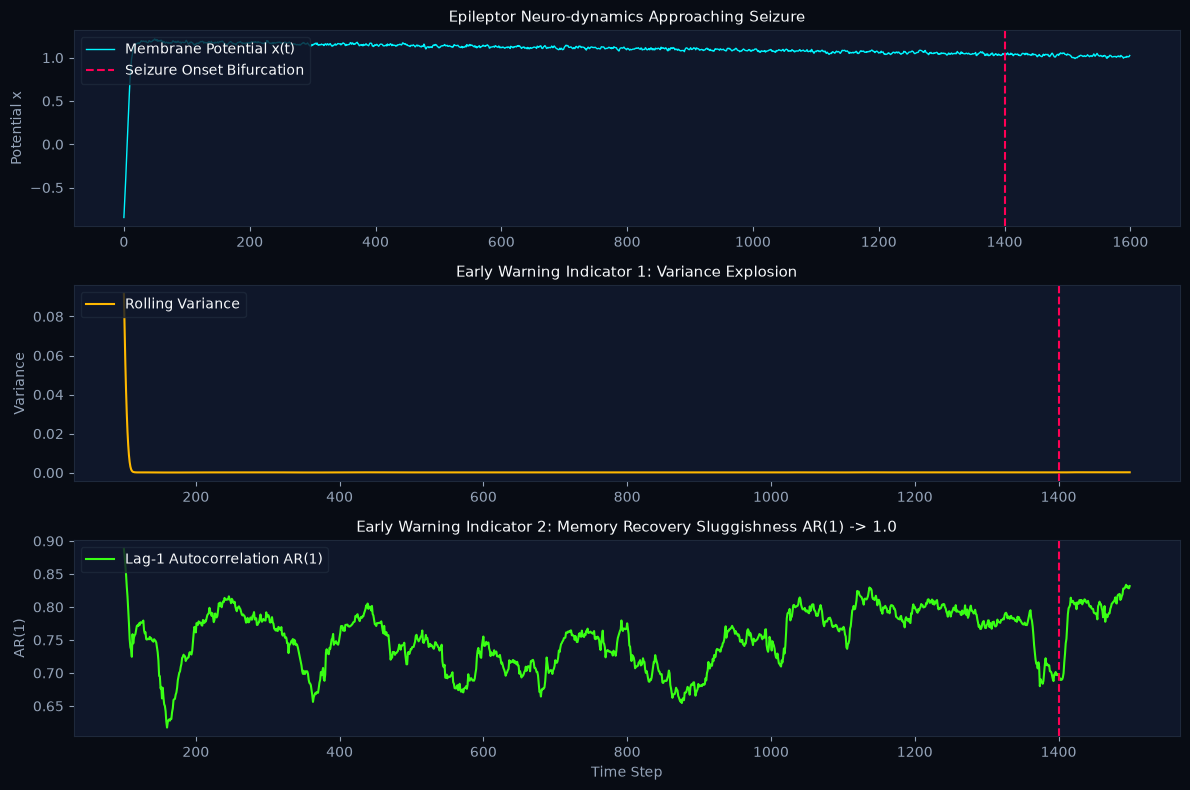

In [8]:
# LAB 8.2: EPILEPTOR SEIZURE DYNAMICS & CRITICAL SLOWING DOWN (CSD)
display(HTML(create_dashboard_header(
    'LAB 8.2: SEIZURE TRANSITION & CRITICAL SLOWING DOWN (CSD)',
    'Track early warning precursors before seizure bifurcation: Observe surges in local variance and AR(1) autocorrelation.'
)))

x_eeg, z_perm, var_c, ar1_c = simulate_epileptor_csd(n_steps=1600)

fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=False, dpi=100)

# Panel A: EEG Signal
axs[0].plot(x_eeg, color=PALETTE['cyan'], lw=1.0, label='Membrane Potential x(t)')
axs[0].axvline(1400, color=PALETTE['crimson'], linestyle='--', lw=1.5, label='Seizure Onset Bifurcation')
axs[0].set_title('Epileptor Neuro-dynamics Approaching Seizure', fontsize=11)
axs[0].set_ylabel('Potential x', fontsize=10)
axs[0].legend(loc='upper left')

# Panel B: Rolling Variance (CSD indicator 1)
axs[1].plot(range(100, 100 + len(var_c)), var_c, color=PALETTE['amber'], lw=1.5, label='Rolling Variance')
axs[1].axvline(1400, color=PALETTE['crimson'], linestyle='--', lw=1.5)
axs[1].set_title('Early Warning Indicator 1: Variance Explosion', fontsize=11)
axs[1].set_ylabel('Variance', fontsize=10)
axs[1].legend(loc='upper left')

# Panel C: Lag-1 Autocorrelation AR(1) (CSD indicator 2)
axs[2].plot(range(100, 100 + len(ar1_c)), ar1_c, color=PALETTE['emerald'], lw=1.5, label='Lag-1 Autocorrelation AR(1)')
axs[2].axvline(1400, color=PALETTE['crimson'], linestyle='--', lw=1.5)
axs[2].set_title('Early Warning Indicator 2: Memory Recovery Sluggishness AR(1) -> 1.0', fontsize=11)
axs[2].set_xlabel('Time Step', fontsize=10)
axs[2].set_ylabel('AR(1)', fontsize=10)
axs[2].legend(loc='upper left')

plt.tight_layout()
plt.show()

In [9]:
# LAB 8.3: FINANCIAL CRASHES & SORNETTE'S LPPLS BUBBLE SINGULARITY
display(HTML(create_dashboard_header(
    'LAB 8.3: FINANCIAL BUBBLES & LOG-PERIODIC ACCELERATION (LPPLS)',
    'Scrub critical time tc and angular frequency omega: Observe faster log-periodic oscillations heading into singularity.'
)))

def render_lppls_dashboard(critical_time, log_freq):
    t_axis, price_s, log_p = generate_lppls_bubble(tc=critical_time, omega=log_freq, n_pts=500)
    
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), dpi=100)
    
    # Panel A: Price Growth
    axs[0].plot(t_axis, price_s, color=PALETTE['cyan'], lw=1.4, label='Synthetic Market Price p(t)')
    axs[0].axvline(critical_time, color=PALETTE['crimson'], linestyle='--', lw=1.5, label=f'Crash Singularity tc={critical_time:.1f}')
    axs[0].set_title('Super-Exponential Price Bubble Acceleration', fontsize=11)
    axs[0].set_xlabel('Time t', fontsize=10)
    axs[0].set_ylabel('Asset Price ($)', fontsize=10)
    axs[0].legend(loc='upper left')
    
    # Panel B: Log Price Curve with Oscillations
    axs[1].plot(t_axis, log_p, color=PALETTE['amber'], lw=1.6, label='ln p(t) Fit')
    axs[1].axvline(critical_time, color=PALETTE['crimson'], linestyle='--', lw=1.5)
    axs[1].set_title(f'Log-Periodic Oscillations | Angular Frequency omega = {log_freq:.1f}', fontsize=11)
    axs[1].set_xlabel('Time t', fontsize=10)
    axs[1].set_ylabel('ln p(t)', fontsize=10)
    axs[1].legend(loc='upper left')
    
    plt.tight_layout()
    plt.show()

s_tc = widgets.FloatSlider(value=100.0, min=80.0, max=120.0, step=2.0, description='Crash tc:', layout=widgets.Layout(width='380px'))
s_om = widgets.FloatSlider(value=6.5, min=3.0, max=12.0, step=0.5, description='Omega:', layout=widgets.Layout(width='380px'))
ui_lppls = widgets.HBox([s_tc, s_om], layout=widgets.Layout(padding='10px', background_color=PALETTE['surface'], border='1px solid ' + PALETTE['border'], border_radius='8px'))
out_lppls = widgets.interactive_output(render_lppls_dashboard, {'critical_time': s_tc, 'log_freq': s_om})
display(ui_lppls, out_lppls)

Output()

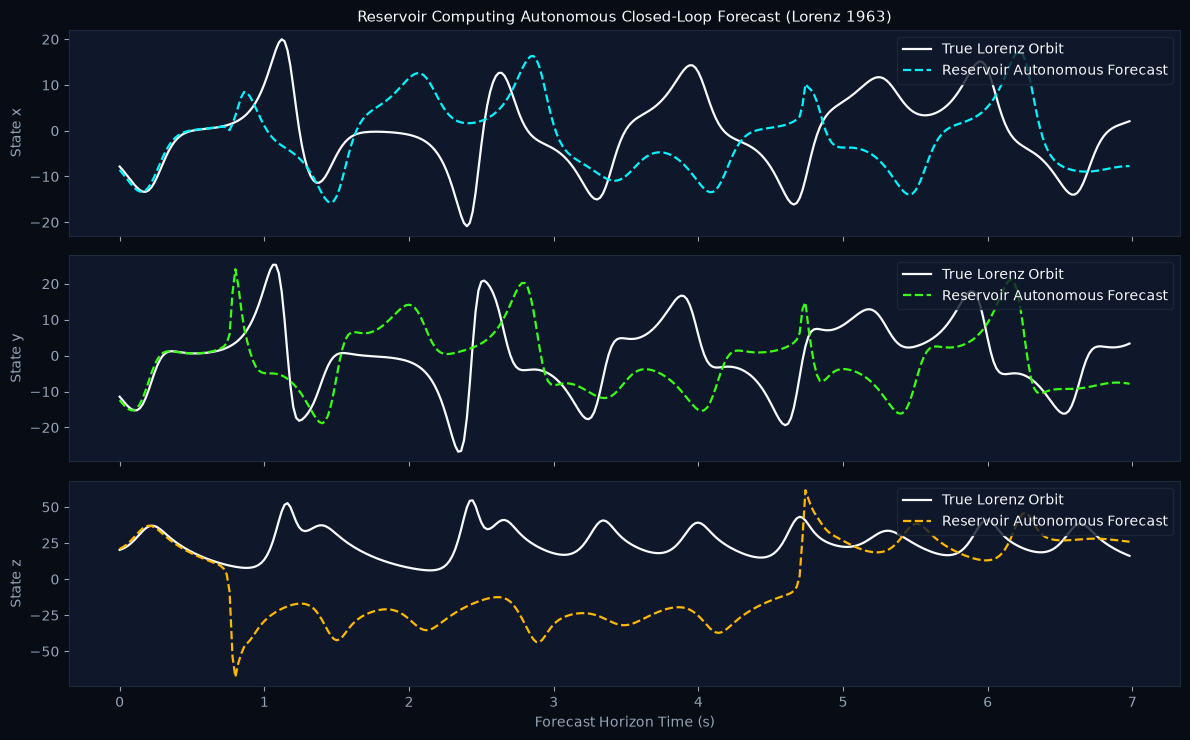

In [10]:
# LAB 8.4: RESERVOIR COMPUTING AUTONOMOUS FORECASTING BEYOND LYAPUNOV TIME
display(HTML(create_dashboard_header(
    'LAB 8.4: RESERVOIR COMPUTING (ESN) AUTONOMOUS CHAOS FORECASTING',
    'Train 400-neuron echo state network on Lorenz system and launch autonomous closed-loop forecasting.'
)))

# 1. Generate standard Lorenz training/testing series
dt = 0.02
total_pts = 2200
x, y, z = 1.0, 1.0, 1.0
lorenz_traj = np.zeros((total_pts, 3))
for i in range(total_pts):
    dx = 10.0 * (y - x)
    dy = 28.0 * x - y - x * z
    dz = x * y - (8.0 / 3.0) * z
    x += dx * dt
    y += dy * dt
    z += dz * dt
    lorenz_traj[i] = [x, y, z]

train_len = 1400
test_len = 350
train_input = lorenz_traj[:train_len]
train_target = lorenz_traj[1 : train_len + 1]
ground_truth_test = lorenz_traj[train_len : train_len + test_len]

# 2. Train Echo State Network
esn = EchoStateNetwork(n_inputs=3, n_reservoir=400, spectral_radius=0.92, alpha=0.85, reg=1e-5)
esn.train(train_input, train_target, warmup=150)
autonomous_pred = esn.forecast_autonomous(n_forecast_steps=test_len)

# 3. Plot comparison
t_eval_axis = np.arange(test_len) * dt
fig, axs = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, dpi=100)

coords = ['x', 'y', 'z']
colors = [PALETTE['cyan'], PALETTE['emerald'], PALETTE['amber']]

for c in range(3):
    axs[c].plot(t_eval_axis, ground_truth_test[:, c], color=PALETTE['text_main'], lw=1.6, label='True Lorenz Orbit')
    axs[c].plot(t_eval_axis, autonomous_pred[:, c], '--', color=colors[c], lw=1.6, label='Reservoir Autonomous Forecast')
    axs[c].set_ylabel(f'State {coords[c]}', fontsize=10)
    axs[c].legend(loc='upper right')

axs[0].set_title('Reservoir Computing Autonomous Closed-Loop Forecast (Lorenz 1963)', fontsize=11)
axs[2].set_xlabel('Forecast Horizon Time (s)', fontsize=10)
plt.tight_layout()
plt.show()